Clocked VAE Model Creation

This notebook creates the VAE model that will be used by the updated Clocked app.

It uses unified_attendance_1250.csv.

The VAE follows the same approach used in the VAE vs One-Class SVM comparison:
- train only on normal labelled attendance
- use reconstruction error as the anomaly score
- use a small VAE with hidden size 32 and latent size 8
- flag records above the normal reconstruction threshold

For the app version, only features that Clocked can really collect or calculate are used. Phone manufacturer/model fields are not used because a browser cannot reliably provide them.


In [14]:
# libraries

import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch:", torch.__version__)


PyTorch: 2.14.1


1. Load the dataset

In [15]:
# load the 1250 row dataset

csv_path = Path("unified_attendance_1250.csv")

if not csv_path.exists():
    csv_path = Path("/mnt/data/unified_attendance_1250.csv")

df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)
print(df["fraud_label"].value_counts(dropna=False))
display(df.head())


Dataset shape: (1250, 32)
fraud_label
0.0    820
NaN    250
1.0    180
Name: count, dtype: int64


,attendance_id,employee_id,job_id,site_id,clock_in_at,clock_out_at,shift_hours,break_minutes,paid_hours,payroll_variance_hours,...,travel_speed_kmh,device_id,phone_manufacturer,phone_model,phone_os,phone_os_version,network_type,network_changed_flag,device_shared_flag,fraud_label
0,AT5C21671A8A0AB,E0001,JOB0028,SITE010,2024-11-08T08:35+05:30,2024-11-08T16:50+05:30,8.2500,30.0,7.7500,0.0,...,64.38,DEV0001,Samsung,Galaxy S22,Android,14,5G,0,0,0.0
1,AT2CD4AE425E0F2,E0013,JOB0001,SITE012,2025-10-12T09:05+05:30,2025-10-12T12:55+05:30,3.8333,0.0,3.8333,0.0,...,28.89,DEV0013,Samsung,Galaxy S22,Android,14,WiFi,0,0,0.0
2,AT72D10B16C8F7E,E0014,JOB0028,SITE010,2025-04-03T08:45+05:30,2025-04-03T17:15+05:30,8.5000,30.0,8.0000,0.0,...,18.68,DEV0023,Samsung,Galaxy A34,Android,14,WiFi,1,0,0.0
3,ATF600BB896C1B3,E0004,JOB0058,SITE005,2025-05-24T07:36+05:30,2025-05-24T15:41+05:30,8.0833,30.0,7.5833,0.0,...,17.84,DEV0029,Xiaomi,Redmi Note 13,Android,14,4G,0,0,0.0
4,ATB1FBD482D62E6,E0001,JOB0056,SITE001,2024-06-25T09:30+05:30,2024-06-25T17:30+05:30,8.0000,30.0,7.5000,0.0,...,13.64,DEV0001,Samsung,Galaxy S22,Android,14,4G,0,0,NaN


2. Prepare Clocked features

In [16]:
# make time features

# keep network labels the same as the browser/API
def normalize_network_type(value):
    if pd.isna(value):
        return "unknown"

    text = str(value).strip().lower().replace("wi-fi", "wifi")
    aliases = {
        "4 g": "4g",
        "5 g": "5g",
        "3 g": "3g",
        "2 g": "2g",
    }
    return aliases.get(text, text or "unknown")

df["network_type"] = df["network_type"].apply(normalize_network_type)


df["clock_in_at"] = pd.to_datetime(df["clock_in_at"], errors="coerce")
df["clock_in_hour"] = df["clock_in_at"].apply(
    lambda value: value.hour + value.minute / 60 if pd.notna(value) else np.nan
)
df["clock_in_day_of_week"] = df["clock_in_at"].apply(
    lambda value: value.dayofweek if pd.notna(value) else np.nan
)

NUMERIC_FEATURES = [
    "shift_hours",
    "break_minutes",
    "paid_hours",
    "previous_shift_gap_hours",
    "has_previous_shift",
    "distance_to_site_m",
    "geofence_radius_m",
    "gps_accuracy_m",
    "travel_speed_kmh",
    "network_changed_flag",
    "device_shared_flag",
    "clock_in_hour",
    "clock_in_day_of_week",
]

CATEGORICAL_FEATURES = [
    "geofence_status",
    "network_type",
]

MODEL_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

labelled = df[df["fraud_label"].notna()].copy()
labelled["fraud_label"] = labelled["fraud_label"].astype(int)

print("Rows with labels:", len(labelled))
print("Normal:", int((labelled["fraud_label"] == 0).sum()))
print("Fraud:", int((labelled["fraud_label"] == 1).sum()))


Rows with labels: 1000
Normal: 820
Fraud: 180


3. Preprocessing

In [17]:
# fit preprocessing only on normal training records

def fit_preprocessor(data):
    numeric_medians = {}
    numeric_means = {}
    numeric_scales = {}

    for column in NUMERIC_FEATURES:
        values = pd.to_numeric(data[column], errors="coerce")
        median = float(values.median())
        filled = values.fillna(median).astype(float)

        mean = float(filled.mean())
        scale = float(filled.std(ddof=0))
        if not np.isfinite(scale) or scale < 1e-9:
            scale = 1.0

        numeric_medians[column] = median
        numeric_means[column] = mean
        numeric_scales[column] = scale

    category_values = {}
    for column in CATEGORICAL_FEATURES:
        values = data[column].fillna("unknown").astype(str)
        category_values[column] = sorted(values.unique().tolist())

    return {
        "numeric_medians": numeric_medians,
        "numeric_means": numeric_means,
        "numeric_scales": numeric_scales,
        "category_values": category_values,
    }


def transform(data, config):
    rows = []

    for _, row in data.iterrows():
        output = []

        for column in NUMERIC_FEATURES:
            value = pd.to_numeric(pd.Series([row[column]]), errors="coerce").iloc[0]
            if pd.isna(value):
                value = config["numeric_medians"][column]

            value = float(value)
            value = (
                value - config["numeric_means"][column]
            ) / config["numeric_scales"][column]

            output.append(value)

        for column in CATEGORICAL_FEATURES:
            value = str(row[column]) if pd.notna(row[column]) else "unknown"

            for category in config["category_values"][column]:
                output.append(1.0 if value == category else 0.0)

        rows.append(output)

    return np.asarray(rows, dtype=np.float32)


4. VAE

In [18]:
class VAE(nn.Module):
    def __init__(self, input_dim, hidden_dim=32, latent_dim=8):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
        )

        self.mu = nn.Linear(hidden_dim, latent_dim)
        self.logvar = nn.Linear(hidden_dim, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
        )

    def encode(self, x):
        hidden = self.encoder(x)
        return self.mu(hidden), self.logvar(hidden)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        noise = torch.randn_like(std)
        return mu + noise * std

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        reconstructed = self.decoder(z)
        return reconstructed, mu, logvar


def vae_loss(reconstructed, original, mu, logvar):
    reconstruction = nn.functional.mse_loss(
        reconstructed,
        original,
        reduction="mean",
    )

    kl = -0.5 * torch.mean(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    return reconstruction + 0.001 * kl


In [19]:
def train_vae(X_train, epochs=100):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    tensor = torch.tensor(X_train, dtype=torch.float32)
    loader = DataLoader(
        TensorDataset(tensor),
        batch_size=32,
        shuffle=True,
    )

    model = VAE(
        input_dim=X_train.shape[1],
        hidden_dim=32,
        latent_dim=8,
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    history = []

    for epoch in range(epochs):
        model.train()
        total = 0.0

        for (batch,) in loader:
            batch = batch.to(device)

            optimizer.zero_grad()
            reconstructed, mu, logvar = model(batch)

            loss = vae_loss(reconstructed, batch, mu, logvar)
            loss.backward()
            optimizer.step()

            total += loss.item() * len(batch)

        history.append(total / len(loader.dataset))

        if (epoch + 1) % 20 == 0:
            print(f"Epoch {epoch + 1}/{epochs} - loss: {history[-1]:.4f}")

    return model, history, device


def reconstruction_error(model, X, device):
    model.eval()

    tensor = torch.tensor(
        X,
        dtype=torch.float32,
        device=device,
    )

    with torch.no_grad():
        # use the latent mean so scoring is stable
        mu, _ = model.encode(tensor)
        reconstructed = model.decoder(mu)

        error = torch.mean(
            (tensor - reconstructed) ** 2,
            dim=1,
        )

    return error.cpu().numpy()


5. Test the VAE before creating the final model

In [20]:
train_df, test_df = train_test_split(
    labelled,
    test_size=0.30,
    random_state=SEED,
    stratify=labelled["fraud_label"],
)

normal_train = train_df[
    train_df["fraud_label"] == 0
].copy()

preprocess_config = fit_preprocessor(normal_train)

X_train = transform(normal_train, preprocess_config)
X_test = transform(test_df, preprocess_config)

y_test = test_df["fraud_label"].to_numpy()

print("Normal training rows:", len(normal_train))
print("Test rows:", len(test_df))
print("Model input size:", X_train.shape[1])


Normal training rows: 574
Test rows: 300
Model input size: 18


Epoch 20/100 - loss: 0.3055
Epoch 40/100 - loss: 0.1411
Epoch 60/100 - loss: 0.1001
Epoch 80/100 - loss: 0.0846
Epoch 100/100 - loss: 0.0725


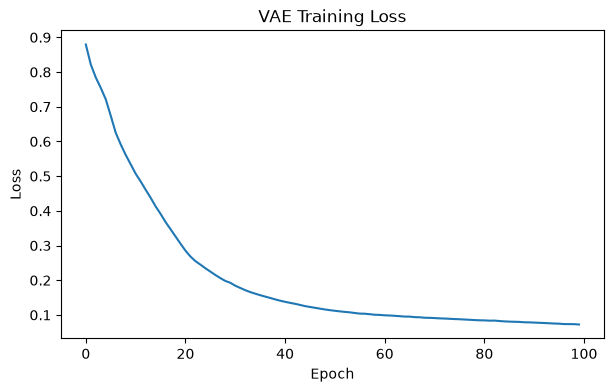

In [21]:
test_model, loss_history, device = train_vae(
    X_train,
    epochs=100,
)

plt.figure(figsize=(7, 4))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VAE Training Loss")
plt.show()


In [22]:
# same threshold method used in the comparison notebook

THRESHOLD_PERCENTILE = 95.0

train_error = reconstruction_error(
    test_model,
    X_train,
    device,
)

test_error = reconstruction_error(
    test_model,
    X_test,
    device,
)

threshold = float(
    np.percentile(
        train_error,
        THRESHOLD_PERCENTILE,
    )
)

prediction = (
    test_error > threshold
).astype(int)

metrics = {
    "accuracy": accuracy_score(y_test, prediction),
    "precision": precision_score(y_test, prediction, zero_division=0),
    "recall": recall_score(y_test, prediction, zero_division=0),
    "f1": f1_score(y_test, prediction, zero_division=0),
    "roc_auc": roc_auc_score(y_test, test_error),
    "pr_auc": average_precision_score(y_test, test_error),
}

print("Threshold percentile:", THRESHOLD_PERCENTILE)
print("Test threshold:", round(threshold, 6))
print()

for name, value in metrics.items():
    print(f"{name}: {value:.4f}")


Threshold percentile: 95.0
Test threshold: 0.173975

accuracy: 0.8067
precision: 0.4667
recall: 0.5185
f1: 0.4912
roc_auc: 0.8003
pr_auc: 0.5390


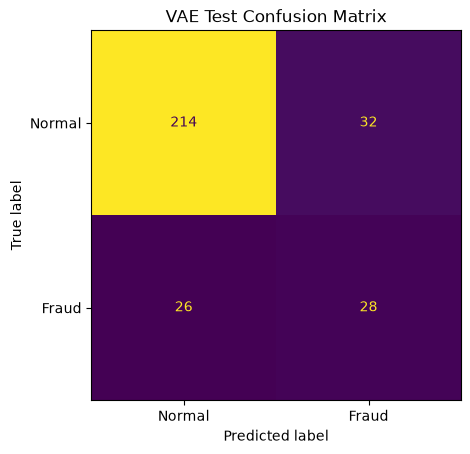

In [23]:
ConfusionMatrixDisplay(
    confusion_matrix(y_test, prediction),
    display_labels=["Normal", "Fraud"],
).plot(colorbar=False)

plt.title("VAE Test Confusion Matrix")
plt.show()


6. Train the final deployment model


In [24]:
final_normal = labelled[
    labelled["fraud_label"] == 0
].copy()

final_preprocess = fit_preprocessor(final_normal)
X_final = transform(final_normal, final_preprocess)

final_model, final_loss, final_device = train_vae(
    X_final,
    epochs=120,
)

final_train_error = reconstruction_error(
    final_model,
    X_final,
    final_device,
)

final_threshold = float(
    np.percentile(
        final_train_error,
        THRESHOLD_PERCENTILE,
    )
)

print("Final normal rows:", len(final_normal))
print("Final input size:", X_final.shape[1])
print("Threshold percentile:", THRESHOLD_PERCENTILE)
print("Final reconstruction threshold:", round(final_threshold, 6))


Epoch 20/120 - loss: 0.2186
Epoch 40/120 - loss: 0.1185
Epoch 60/120 - loss: 0.0913
Epoch 80/120 - loss: 0.0786
Epoch 100/120 - loss: 0.0718
Epoch 120/120 - loss: 0.0659
Final normal rows: 820
Final input size: 18
Threshold percentile: 95.0
Final reconstruction threshold: 0.140278


7. Save the deployable model

In [25]:
output_dir = Path("clocked_vae_output")
output_dir.mkdir(exist_ok=True)

model_path = output_dir / "clocked_vae_bundle.pt"
metadata_path = output_dir / "clocked_vae_metadata.json"
results_path = output_dir / "clocked_vae_test_results.csv"

bundle = {
    "bundle_version": 1,
    "model_name": "clocked_vae",
    "model_state_dict": final_model.cpu().state_dict(),

    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,

    "numeric_medians": final_preprocess["numeric_medians"],
    "numeric_means": final_preprocess["numeric_means"],
    "numeric_scales": final_preprocess["numeric_scales"],
    "category_values": final_preprocess["category_values"],

    "input_dim": int(X_final.shape[1]),
    "hidden_dim": 32,
    "latent_dim": 8,

    "reconstruction_threshold": final_threshold,
    "threshold_percentile": THRESHOLD_PERCENTILE,

    "training_seed": SEED,
    "normal_training_rows": int(len(final_normal)),
}

torch.save(bundle, model_path)

metadata = {
    "model": "Variational Autoencoder",
    "dataset": csv_path.name,
    "normal_training_rows": int(len(final_normal)),
    "input_dim": int(X_final.shape[1]),
    "hidden_dim": 32,
    "latent_dim": 8,
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "reconstruction_threshold": final_threshold,
    "threshold_percentile": THRESHOLD_PERCENTILE,
    "test_metrics_before_final_retraining": {
        name: float(value)
        for name, value in metrics.items()
    },
    "notes": [
        "The final VAE is trained only on labelled normal records.",
        "The threshold is the 95th percentile of normal training reconstruction error.",
        "The 250 unlabelled historical records are not assumed to be normal.",
        "Phone manufacturer and phone model are not deployment features.",
        "IP changes in Clocked are mapped to network_changed_flag.",
        "The model is intended to flag attendance for manager review, not automatically change payroll.",
    ],
}

metadata_path.write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8",
)

test_results = test_df[
    ["attendance_id", "employee_id", "fraud_label"]
].copy()

test_results["reconstruction_error"] = test_error
test_results["threshold"] = threshold
test_results["predicted_fraud"] = prediction

test_results.to_csv(
    results_path,
    index=False,
)

print("Saved:")
print(model_path)
print(metadata_path)
print(results_path)


Saved:
clocked_vae_output/clocked_vae_bundle.pt
clocked_vae_output/clocked_vae_metadata.json
clocked_vae_output/clocked_vae_test_results.csv


8. Check the saved model

In [26]:
saved = torch.load(
    model_path,
    map_location="cpu",
    weights_only=False,
)

loaded_model = VAE(
    input_dim=saved["input_dim"],
    hidden_dim=saved["hidden_dim"],
    latent_dim=saved["latent_dim"],
)

loaded_model.load_state_dict(
    saved["model_state_dict"]
)

loaded_model.eval()

print("Model loaded successfully")
print("Input size:", saved["input_dim"])
print("Threshold:", saved["reconstruction_threshold"])
print()

Model loaded successfully
Input size: 18
Threshold: 0.140278160572052

